In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import torch 

In [3]:
pip list

Package                               Version             Editable project location
------------------------------------- ------------------- -------------------------
absl-py                               1.4.0
accelerate                            1.8.1
aiofiles                              22.1.0
aiohappyeyeballs                      2.6.1
aiohttp                               3.12.13
aiosignal                             1.3.2
aiosqlite                             0.21.0
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.11.1
alembic                               1.16.2
altair                                5.5.0
annotated-types                       0.7.0
annoy                                 1.17.3
ansicolors                            1.1.8
antlr4-python3-runtime                4.9.3
anyio                                 4.9.0
argon2-cffi                     

In [4]:
my_torch = torch.arange(0,10,1)
my_torch.reshape(2,-1)

tensor([[0, 1, 2, 3, 4],
        [5, 6, 7, 8, 9]])

In [5]:
a = torch.tensor([1,2,3,4])
b = torch.tensor([6,7,8,9])
a+b

tensor([ 7,  9, 11, 13])

In [6]:
a = a.reshape([-1,2])
b = b.reshape([2,-1])
a.add_(b)


tensor([[ 7,  9],
        [11, 13]])

simple nural network function reshape , view
torch.tensor()


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F


for py torch 
first crate a class for model inhariate the nn.module
in init carte a super method to extended the class method in oure calss 
than in method mention how many input ,hidden and output layer we need for this thing 
than crate a 
pass 

In [8]:
class Model(nn.Module):
    def __init__(self , in_features = 4 ,h1=6,h2=5,out_features =3):
            super().__init__()
            self.fc1 =   nn.Linear(in_features ,h1)
            self.fc2 = nn.Linear(h1,h2)
            self.out = nn.Linear(h2,out_features)
    def forward(self,x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)
        return x

In [9]:
torch.manual_seed(41)
model = Model()

In [10]:
import matplotlib.pyplot as plt
import pandas as pd 
%matplotlib inline


In [11]:
p = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data",names = [1,2,3,4,5])
pd.set_option('future.no_silent_downcasting', True)
p[5]  = p[5].replace("Iris-setosa",0.0)
p[5]  = p[5].replace("Iris-virginica",1.0)
p[5]  = p[5].replace("Iris-versicolor",2.0)
p[5]=p[5].astype(int)

In [12]:
X = p.drop(5,axis=1)
Y= p.drop([1,2,3,4],axis=1)
x=X.values 
y=Y.values


In [13]:
from sklearn.model_selection import train_test_split

In [14]:
x_train,x_test,y_train ,y_test = train_test_split(x,y,test_size=0.2,random_state=32)


In [15]:
x_train=torch.FloatTensor(x_train)
x_test=torch.FloatTensor(x_test)



In [16]:
y_train=torch.LongTensor(y_train )
y_test=torch.LongTensor(y_test)
y_train= y_train.reshape(1,-1)[0]
y_test= y_test.reshape(1,-1)[0]

In [17]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
epochs =1000
losses = []
for i in range(epochs):
    y_pred = model.forward(x_train)
    loss = criterion(y_pred,y_train)
    losses.append(loss.detach().numpy()) 
    print(loss)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

tensor(1.1148, grad_fn=<NllLossBackward0>)
tensor(1.1139, grad_fn=<NllLossBackward0>)
tensor(1.1130, grad_fn=<NllLossBackward0>)
tensor(1.1122, grad_fn=<NllLossBackward0>)
tensor(1.1114, grad_fn=<NllLossBackward0>)
tensor(1.1106, grad_fn=<NllLossBackward0>)
tensor(1.1098, grad_fn=<NllLossBackward0>)
tensor(1.1091, grad_fn=<NllLossBackward0>)
tensor(1.1084, grad_fn=<NllLossBackward0>)
tensor(1.1077, grad_fn=<NllLossBackward0>)
tensor(1.1071, grad_fn=<NllLossBackward0>)
tensor(1.1065, grad_fn=<NllLossBackward0>)
tensor(1.1059, grad_fn=<NllLossBackward0>)
tensor(1.1053, grad_fn=<NllLossBackward0>)
tensor(1.1048, grad_fn=<NllLossBackward0>)
tensor(1.1042, grad_fn=<NllLossBackward0>)
tensor(1.1037, grad_fn=<NllLossBackward0>)
tensor(1.1032, grad_fn=<NllLossBackward0>)
tensor(1.1027, grad_fn=<NllLossBackward0>)
tensor(1.1022, grad_fn=<NllLossBackward0>)
tensor(1.1018, grad_fn=<NllLossBackward0>)
tensor(1.1013, grad_fn=<NllLossBackward0>)
tensor(1.1009, grad_fn=<NllLossBackward0>)
tensor(1.10

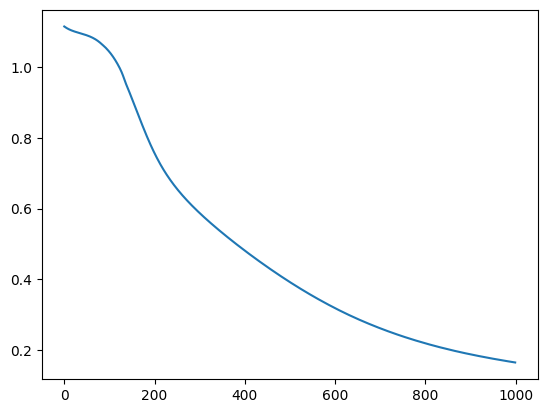

In [18]:
plt.plot(range(epochs),losses)

In [19]:
c=0
with torch.no_grad():
    y_pred = model.forward(x_test)
    loss = criterion(y_pred,y_test)
    for i,data in enumerate(x_test): 
     y_eval = model.forward(data)
     print(y_eval.argmax().item(),"  ->",y_test[i])
     if(y_eval.argmax().item()==y_test[i]):
       c+=1
print(c)
print(loss)

2   -> tensor(2)
0   -> tensor(0)
0   -> tensor(0)
2   -> tensor(2)
1   -> tensor(1)
1   -> tensor(1)
0   -> tensor(0)
0   -> tensor(0)
2   -> tensor(2)
0   -> tensor(0)
2   -> tensor(2)
1   -> tensor(1)
2   -> tensor(2)
2   -> tensor(2)
1   -> tensor(1)
1   -> tensor(1)
2   -> tensor(2)
1   -> tensor(1)
2   -> tensor(2)
0   -> tensor(0)
0   -> tensor(0)
1   -> tensor(1)
1   -> tensor(1)
0   -> tensor(0)
0   -> tensor(0)
2   -> tensor(2)
0   -> tensor(0)
1   -> tensor(1)
0   -> tensor(0)
0   -> tensor(0)
30
tensor(0.1402)


In [20]:
with torch.no_grad():
  x = torch.tensor([100.0,100.,70.0,5.00])
  print(model(x))

tensor([  92.7425, -196.8683,  -15.7018])


how save model 